# 01 · UV-Vis Calibration: Verifying the Beer-Lambert Law for Potassium Dichromate

**Source:** my own first-year practical data (SFC1003, Experiment 3, Part a), University of Huddersfield.
**Technique:** UV-Vis spectrophotometry at 440 nm.

During the practical I plotted the calibration graph by hand and read off a molar absorption coefficient of **ε = 348 M⁻¹ cm⁻¹**.
In this notebook I re-analyse the same readings in Python, the way a QC lab would validate a calibration:

1. Rebuild the standard concentrations from the dilution scheme
2. Fit the calibration line by least-squares regression and get ε with a 95% confidence interval
3. Check linearity with a residual plot and decide whether the intercept is needed
4. Estimate the limit of detection (LOD) and limit of quantification (LOQ)
5. Use the calibration to convert real sample absorbances into concentrations (these feed into Notebook 02)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Raw data

Each standard was made by taking 10 cm³ of the K₂Cr₂O₇ stock (0.0040 M) and adding water. The blank (0 cm³ dichromate) was used to zero the instrument.

On my pro-forma I rounded the concentrations to 2 significant figures (e.g. 0.0013 M instead of 0.001333 M). Here I recalculate them exactly from the dilution, using C₁V₁ = C₂V₂, so rounding doesn't bias the slope.

In [2]:
stock_M = 0.0040          # mol dm-3
path_cm = 1.0             # standard 1 cm cuvette

raw = pd.DataFrame({
    "V_dichromate_cm3": [0, 10, 10, 10, 10, 10, 10],
    "V_water_cm3":      [10, 0, 10, 20, 30, 40, 50],
    "A_440":            [0.000, 1.368, 0.669, 0.481, 0.367, 0.286, 0.251],
    "conc_on_proforma_M": [0.000, 0.0040, 0.0020, 0.0013, 0.0010, 0.0008, 0.0007],
})

raw["conc_exact_M"] = stock_M * raw["V_dichromate_cm3"] / (raw["V_dichromate_cm3"] + raw["V_water_cm3"])
raw["rounding_error_%"] = np.where(raw["conc_exact_M"] > 0,
                                   100 * (raw["conc_on_proforma_M"] - raw["conc_exact_M"]) / raw["conc_exact_M"], 0)
raw.round(6)

,V_dichromate_cm3,V_water_cm3,A_440,conc_on_proforma_M,conc_exact_M,rounding_error_%
0,0,10,0.000,0.0000,0.000000,0.0
1,10,0,1.368,0.0040,0.004000,0.0
2,10,10,0.669,0.0020,0.002000,0.0
3,10,20,0.481,0.0013,0.001333,-2.5
4,10,30,0.367,0.0010,0.001000,0.0
5,10,40,0.286,0.0008,0.000800,0.0
6,10,50,0.251,0.0007,0.000667,5.0


Rounding put the 0.000667 M standard about 5% too high. That's small, but it's a systematic error that matters most at the low end of the calibration, which is the part that sets the detection limit.

## 2. Least-squares calibration

Beer-Lambert: **A = ε·l·c**, so a plot of A against c should be a straight line through the origin with slope ε·l.

I fit the six standards (the blank was used to zero the spectrophotometer, so it isn't an independent measurement) and then check whether the intercept is statistically different from zero.

In [3]:
std = raw[raw["V_dichromate_cm3"] > 0].copy()
x = std["conc_exact_M"].to_numpy()
y = std["A_440"].to_numpy()
n = len(x)

fit = stats.linregress(x, y)
t95 = stats.t.ppf(0.975, n - 2)

eps = fit.slope / path_cm
eps_ci = t95 * fit.stderr / path_cm
int_ci = t95 * fit.intercept_stderr

print(f"Slope (ε·l)        = {fit.slope:.1f} ± {t95*fit.stderr:.1f}  (95% CI)")
print(f"ε                  = {eps:.0f} ± {eps_ci:.0f} M⁻¹ cm⁻¹")
print(f"Intercept          = {fit.intercept:.4f} ± {int_ci:.4f}")
print(f"R²                 = {fit.rvalue**2:.5f}")
print(f"Intercept CI contains zero? {abs(fit.intercept) < int_ci}")

Slope (ε·l)        = 334.2 ± 14.5  (95% CI)
ε                  = 334 ± 14 M⁻¹ cm⁻¹
Intercept          = 0.0245 ± 0.0288
R²                 = 0.99903
Intercept CI contains zero? True


In [4]:
# Fit forced through the origin, which is what Beer-Lambert predicts
eps0 = (x @ y) / (x @ x) / path_cm
print(f"ε (through origin) = {eps0:.0f} M⁻¹ cm⁻¹")
print(f"ε (my hand graph)  = 348 M⁻¹ cm⁻¹")
print(f"Difference from hand graph: {100*(348-eps)/eps:+.1f}% vs free fit, {100*(348-eps0)/eps0:+.1f}% vs origin fit")

ε (through origin) = 344 M⁻¹ cm⁻¹
ε (my hand graph)  = 348 M⁻¹ cm⁻¹
Difference from hand graph: +4.1% vs free fit, +1.1% vs origin fit


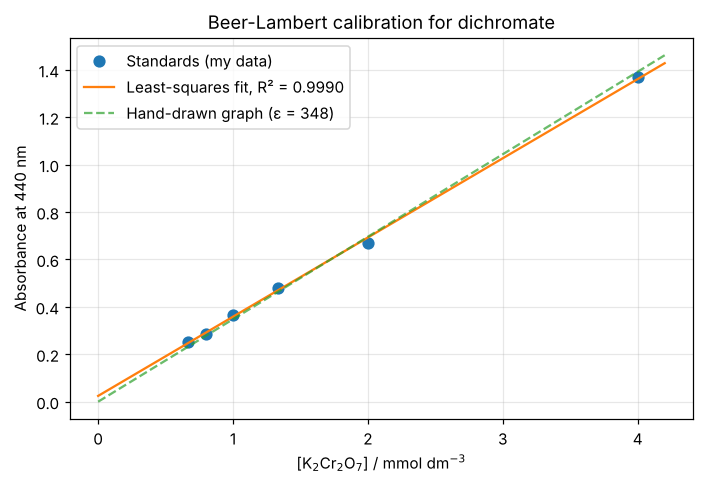

In [5]:
xx = np.linspace(0, x.max() * 1.05, 100)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(x * 1e3, y, "o", ms=7, label="Standards (my data)")
ax.plot(xx * 1e3, fit.intercept + fit.slope * xx, "-", label=f"Least-squares fit, R² = {fit.rvalue**2:.4f}")
ax.plot(xx * 1e3, 348 * path_cm * xx, "--", alpha=0.7, label="Hand-drawn graph (ε = 348)")
ax.set_xlabel("[K$_2$Cr$_2$O$_7$] / mmol dm$^{-3}$")
ax.set_ylabel("Absorbance at 440 nm")
ax.set_title("Beer-Lambert calibration for dichromate")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Is it really linear? Residual analysis

A high R² on its own doesn't prove a calibration is linear. The residuals (measured − predicted) should scatter randomly around zero. A curved pattern means the response is bending, which can happen at high absorbance.

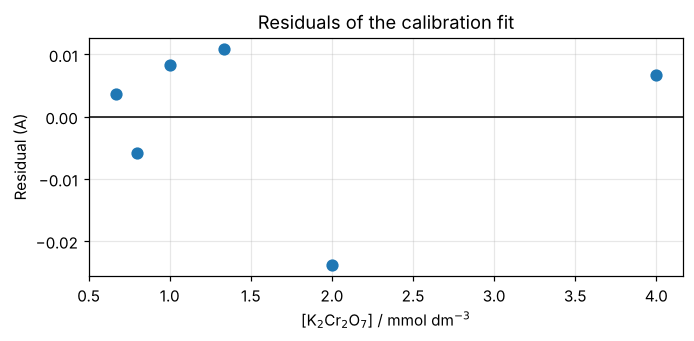

Standard error of regression s(y/x) = 0.0146 absorbance units


,conc_exact_M,A_440,A_pred,residual,residual_%
1,0.0040,1.368,1.3612,0.0068,0.4970
2,0.0020,0.669,0.6929,-0.0239,-3.4447
3,0.0013,0.481,0.4701,0.0109,2.3234
4,0.0010,0.367,0.3587,0.0083,2.3186
5,0.0008,0.286,0.2918,-0.0058,-2.0034
6,0.0007,0.251,0.2473,0.0037,1.5007


In [6]:
std["A_pred"] = fit.intercept + fit.slope * x
std["residual"] = y - std["A_pred"]
std["residual_%"] = 100 * std["residual"] / std["A_pred"]
s_yx = np.sqrt(np.sum(std["residual"]**2) / (n - 2))   # standard error of the regression

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.axhline(0, color="k", lw=1)
ax.plot(x * 1e3, std["residual"], "o", ms=7)
ax.set_xlabel("[K$_2$Cr$_2$O$_7$] / mmol dm$^{-3}$")
ax.set_ylabel("Residual (A)")
ax.set_title("Residuals of the calibration fit")
plt.tight_layout()
plt.show()

print(f"Standard error of regression s(y/x) = {s_yx:.4f} absorbance units")
std[["conc_exact_M", "A_440", "A_pred", "residual", "residual_%"]].round(4)

**What the residuals show:** they're small (all within about ±0.025 absorbance units) and show no curved trend, so a straight line suits this range. The one standard that stands out is **0.0020 M, which reads about 3% low**. Every other point is within ±2.5%. A single low point like that is more likely a preparation error, such as a slightly short pipette delivery or an incompletely mixed flask, than a failure of Beer-Lambert. With duplicate standards I could confirm that. Here I keep the point in the fit because I have no experimental reason to reject it.

## 4. Limit of detection and limit of quantification

Using the ICH Q2 approach based on the calibration curve:

- **LOD = 3.3 × s(y/x) / slope**: the lowest concentration that can be reliably *detected*
- **LOQ = 10 × s(y/x) / slope**: the lowest concentration that can be *quantified* with acceptable precision

In [7]:
LOD = 3.3 * s_yx / fit.slope
LOQ = 10 * s_yx / fit.slope
print(f"LOD ≈ {LOD*1e3:.3f} mmol dm⁻³  ({LOD*294.18*1e3:.1f} mg dm⁻³ as K₂Cr₂O₇)")
print(f"LOQ ≈ {LOQ*1e3:.3f} mmol dm⁻³  ({LOQ*294.18*1e3:.1f} mg dm⁻³ as K₂Cr₂O₇)")
print(f"Lowest standard = {x.min()*1e3:.3f} mmol dm⁻³  →  above LOQ? {x.min() > LOQ}")

LOD ≈ 0.144 mmol dm⁻³  (42.4 mg dm⁻³ as K₂Cr₂O₇)
LOQ ≈ 0.437 mmol dm⁻³  (128.5 mg dm⁻³ as K₂Cr₂O₇)
Lowest standard = 0.667 mmol dm⁻³  →  above LOQ? True


These detection limits are fairly high because s(y/x) is inflated by the one low 0.0020 M standard. That's an honest result for a six-point teaching calibration. A validated method would use more replicates and a narrower linear range.

## 5. Using the calibration: converting kinetics readings to concentration

In Part (b) of the same practical I followed the absorbance of dichromate over 90 minutes as it oxidised ethanol. Inverse prediction (c = (A − intercept) / slope) turns those absorbances into concentrations, and these are the inputs for **Notebook 02**.

I also estimate the uncertainty of each predicted concentration using the standard formula for inverse prediction from a calibration line.

In [8]:
kin = pd.DataFrame({
    "time_min": [5, 10, 20, 30, 40, 50, 60, 70, 80, 90],
    "A_440":    [0.931, 0.721, 0.461, 0.289, 0.226, 0.196, 0.148, 0.130, 0.115, 0.110],
})

xbar = x.mean(); Sxx = np.sum((x - xbar)**2)
def inverse_predict(A0, m=1):
    c = (A0 - fit.intercept) / fit.slope
    s_c = (s_yx / fit.slope) * np.sqrt(1/m + 1/n + (A0 - y.mean())**2 / (fit.slope**2 * Sxx))
    return c, s_c

kin["conc_M"], kin["s_conc_M"] = inverse_predict(kin["A_440"].to_numpy())
kin["below_LOQ"] = kin["conc_M"] < LOQ
kin.round(6)

,time_min,A_440,conc_M,s_conc_M,below_LOQ
0,5,0.931,0.002713,0.000050,False
1,10,0.721,0.002084,0.000048,False
2,20,0.461,0.001306,0.000047,False
3,30,0.289,0.000791,0.000049,False
4,40,0.226,0.000603,0.000050,False
5,50,0.196,0.000513,0.000050,False
6,60,0.148,0.000370,0.000051,True
7,70,0.130,0.000316,0.000051,True
8,80,0.115,0.000271,0.000052,True
9,90,0.110,0.000256,0.000052,True


The last few time points fall below the LOQ, so their concentrations are less certain. I keep that in mind when choosing a kinetic model in Notebook 02. That's also where the absorbance stops falling and levels off, which turns out to be the most interesting part of the dataset.

## Summary

| Parameter | Value |
|---|---|
| ε at 440 nm (free least-squares fit) | 334 ± 14 M⁻¹ cm⁻¹ (95% CI) |
| ε at 440 nm (fit through origin) | 344 M⁻¹ cm⁻¹ |
| ε from my hand-drawn graph | 348 M⁻¹ cm⁻¹ |
| R² | 0.999 |
| Intercept | not significantly different from zero |
| Linearity | no curvature; one standard (0.0020 M) about 3% low |
| LOD / LOQ | 0.14 / 0.44 mmol dm⁻³ |

**What I learned from re-analysing this practical in Python:**
- My hand-drawn value (348) agrees with the through-origin regression (344) to about 1%, and it sits inside the 95% confidence interval of the free fit. The regression adds that **confidence interval**, which a hand graph can't give.
- The intercept isn't significantly different from zero, which supports forcing the line through the origin, as Beer-Lambert predicts.
- Rounding concentrations on the pro-forma introduced a small systematic error that's easy to avoid in code.
- R² = 0.999 looks perfect, but only the **residual plot** showed that one standard was off.
- A calibration isn't just a slope: LOD/LOQ and inverse-prediction uncertainty decide which later measurements I can trust.